# 07 - Grad-CAM and the inside-brain ratio (Week 9)

Grad-CAM shows where a network looked when it chose its **predicted** class. We run it on **every test image of all 12 runs** and measure the
**inside-brain ratio**: the share of the heat that lies inside the brain,

`ratio = (sum of heat inside the brain mask) / (sum of all heat)`.

The brain mask is: Otsu threshold -> keep the largest connected component -> fill holes. Because the brain covers only part of the picture
(`mask_frac`, about half), a perfectly *uniform* heat map would score exactly `mask_frac`; so every ratio is also compared with that **chance level**
(`ratio_over_chance = ratio / mask_frac`, 1.0 = no better than uniform).

Code: `src/gradcam.py`. Target layer (7 x 7 map at 224 input): MobileNetV3 `blocks[-1]`, EfficientNet `bn2`, ResNet-50 `layer4[-1]`, VGG16 `features[-1]`.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, torch, cv2
import matplotlib.pyplot as plt
from IPython.display import Image as ShowImage, display
from src import gradcam as gc
from src.data import CLASSES, _save
from src.evaluate import make_dataset
RUNS = Path('outputs/runs'); PLOTS = Path('outputs/plots/week9')
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 100)
print('torch', torch.__version__, '| CUDA', torch.cuda.is_available(), '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else '-')
print('tiny-mask flag: brain mask covers less than', gc.TINY_MASK, 'of the picture')

D:\Brain-Tumor\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.14.1+cu126 | CUDA True | NVIDIA GeForce GTX 1650 Ti
tiny-mask flag: brain mask covers less than 0.25 of the picture


## 1. The brain mask (check before trusting any ratio)
Top row = masks of median size, bottom row = the **smallest** masks of the v1 clean test set (cyan outline).
Small masks mean the Otsu step found only part of the head (faint or fragmented tissue), so those images are flagged (`tiny_mask`) and a sensitivity table without them is shown in section 4.

mask / ratio unit checks OK


mask_frac over 520 test images: min 0.015, median 0.595, max 0.766; below 0.25: 10


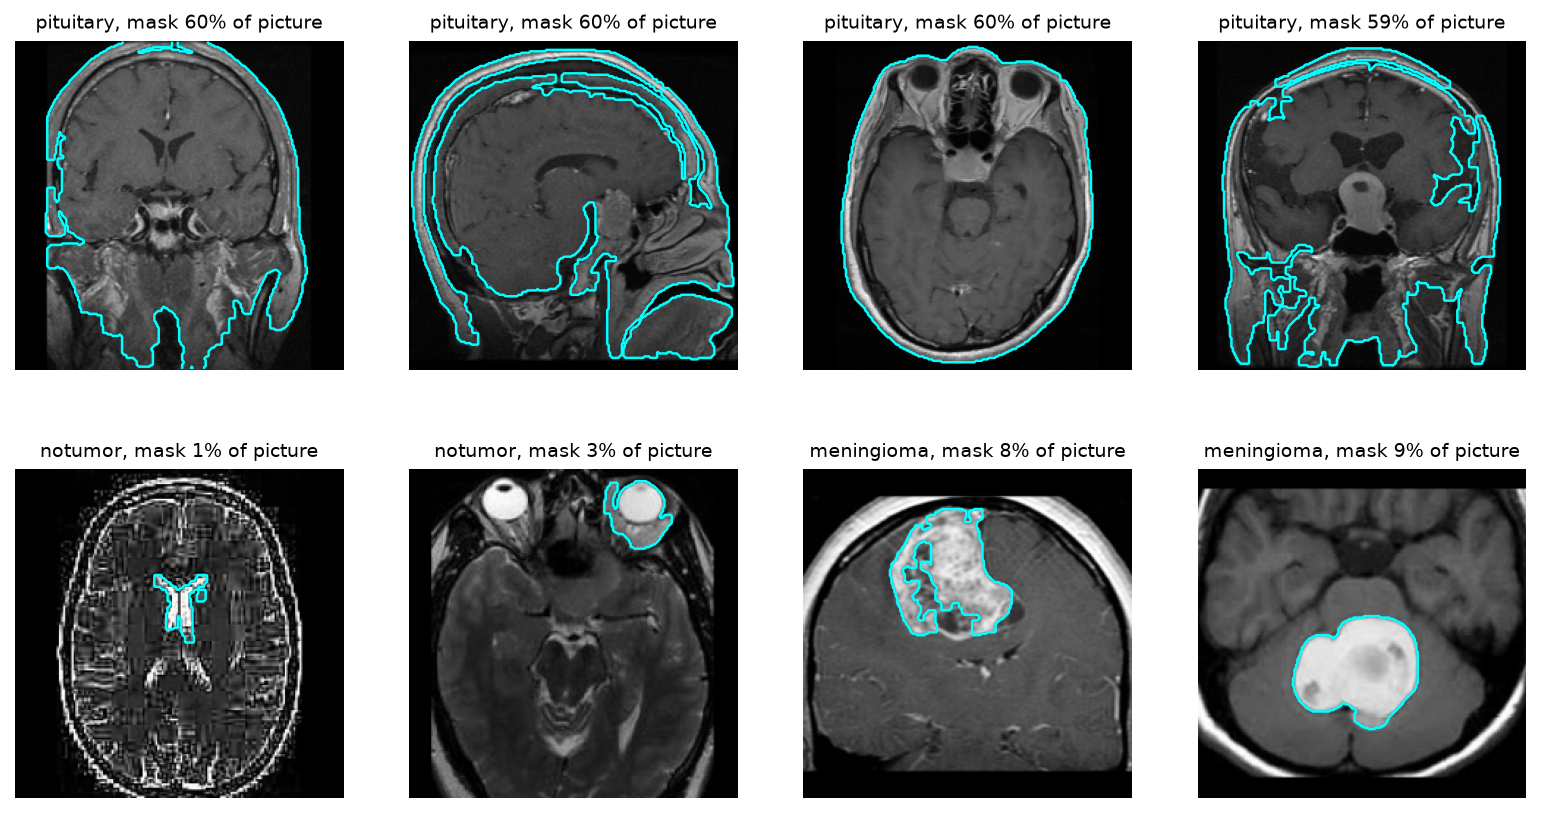

In [2]:
# 1) unit check on a synthetic picture: bright disc with a dark hole + a small bright speck far away
img = np.zeros((224, 224), np.uint8)
cv2.circle(img, (112, 112), 70, 200, -1); cv2.circle(img, (112, 112), 15, 20, -1); cv2.circle(img, (20, 20), 4, 255, -1)
m = gc.inside_mask(img)
assert m[112, 112] and not m[20, 20], 'hole must be filled, speck removed'
assert np.isclose(gc.inside_ratio(np.ones((224, 224), np.float32), m)[0], m.mean()), 'uniform heat map must score mask_frac'
assert gc.inside_ratio(np.zeros((224, 224), np.float32), m) == (0.0, True)
print('mask / ratio unit checks OK')

# 2) mask fraction of every v1 clean test image
ds = make_dataset(json.loads((RUNS / 'v1_clean' / 'mobilenetv3_small_100' / 'config.json').read_text()), 'test')
frac = np.array([gc.inside_mask(gc.load_grey(p)).mean() for p in ds.table['path']])
print('mask_frac over', len(frac), 'test images: min %.3f, median %.3f, max %.3f; below %.2f: %d' % (frac.min(), np.median(frac), frac.max(), gc.TINY_MASK, (frac < gc.TINY_MASK).sum()))
order = np.argsort(frac)
mid = np.argsort(np.abs(frac - np.median(frac)))[:4]
picks = list(mid) + list(order[:4])
fig, axes = plt.subplots(2, 4, figsize=(13, 6.8))
for ax, i in zip(axes.ravel(), picks):
    grey = gc.load_grey(ds.table.loc[i, 'path'])
    ax.imshow(grey, cmap='gray'); ax.contour(gc.inside_mask(grey), levels=[0.5], colors='cyan', linewidths=1.2)
    ax.set_title('%s, mask %.0f%% of picture' % (ds.table.loc[i, 'label'], 100 * frac[i]), fontsize=9); ax.axis('off')
display(ShowImage(str(_save(fig, PLOTS, 'mask_examples.png'))))

## 2. Smoke test (first 40 test images of each architecture, v1 clean)
Checks: heat maps are not empty, ratios are inside [0, 1], no NaN, and the predicted class used for Grad-CAM equals the Week-8 prediction.

In [3]:
for run in ['v1_clean/mobilenetv3_small_100', 'v1_clean/efficientnet_b0', 'v1_clean/resnet50', 'v1_clean/vgg16']:
    d = gc.gradcam_run(RUNS / run, limit=40)
    assert len(d) == 40 and not d.isna().any().any()
    assert d['inside_ratio'].between(0, 1).all() and not d['empty_cam'].any() and d['same_pred_as_week8'].all()
    print('%-32s OK: ratio %.2f-%.2f (mean %.2f), mask_frac mean %.2f' % (run, d['inside_ratio'].min(), d['inside_ratio'].max(), d['inside_ratio'].mean(), d['mask_frac'].mean()))

v1_clean/mobilenetv3_small_100   OK: ratio 0.34-0.94 (mean 0.71), mask_frac mean 0.58


v1_clean/efficientnet_b0         OK: ratio 0.33-1.00 (mean 0.77), mask_frac mean 0.58


v1_clean/resnet50                OK: ratio 0.73-0.99 (mean 0.92), mask_frac mean 0.58


v1_clean/vgg16                   OK: ratio 0.06-0.68 (mean 0.36), mask_frac mean 0.58


## 3. Grad-CAM on every test image of all 12 runs
One run at a time; per-run results are saved in `outputs/gradcam/<run>/inside_ratio.csv`, so a re-run skips finished runs. Heat maps themselves are not stored (only the numbers).

In [4]:
df = gc.gradcam_all()
print(df.shape, '| NaN cells:', int(df.isna().sum().sum()))

v1_clean_efficientnet_b0                 already done


v1_clean_mobilenetv3_small_100           already done


v1_clean_resnet50                        already done


v1_clean_vgg16                           already done


v1_original_efficientnet_b0              already done


...

v2_clean_efficientnet_b0                 already done


v2_clean_mobilenetv3_small_100           already done


v2_original_efficientnet_b0              already done


v2_original_mobilenetv3_small_100        already done


(11600, 13) | NaN cells: 0


In [5]:
# consistency with Week 8: one row per test image, and accuracy recomputed from this table equals the Week-8 accuracy
w8 = pd.read_csv('outputs/results/week8_results.csv')
w8['run'] = w8['version'] + '_' + w8['split'] + '_' + w8['model']
chk = df.groupby('run').agg(n=('row', 'size'), acc=('correct', 'mean')).join(w8.set_index('run')[['n_test', 'accuracy']])
assert (chk['n'] == chk['n_test']).all() and np.allclose(chk['acc'], chk['accuracy']), 'rows or accuracy differ from Week 8'
print('rows and accuracy match Week 8 for all', len(chk), 'runs | Grad-CAM class differs from the Week-8 prediction in', int((~df['same_pred_as_week8']).sum()), 'images')

rows and accuracy match Week 8 for all 12 runs | Grad-CAM class differs from the Week-8 prediction in 0 images


## 4. Inside-brain ratio: per run, per class, correct vs wrong
`n` is always shown: the *wrong* groups are small (a few to about 100 images), so read their numbers with care. No significance test is used.
`chance` = average share of the picture covered by the brain mask; `over_chance_median` = median of ratio / mask_frac.

In [6]:
S = gc.summarise(df)
S['per_run'].round(3)

,n,ratio_mean,ratio_median,chance,over_chance_median,tiny_masks,empty_cams
run,,,,,,,
v1_clean_efficientnet_b0,520.0,0.760,0.798,0.579,1.332,10,0
v1_clean_mobilenetv3_small_100,520.0,0.686,0.726,0.579,1.220,10,0
v1_clean_resnet50,520.0,0.899,0.934,0.579,1.543,10,0
v1_clean_vgg16,520.0,0.353,0.315,0.579,0.523,10,2
v1_original_efficientnet_b0,1311.0,0.701,0.822,0.572,1.347,33,0
v1_original_mobilenetv3_small_100,1311.0,0.638,0.657,0.572,1.145,33,0
v1_original_resnet50,1311.0,0.849,0.880,0.572,1.486,33,0
v1_original_vgg16,1311.0,0.531,0.534,0.572,0.906,33,0
v2_clean_efficientnet_b0,538.0,0.783,0.823,0.578,1.360,9,0


In [7]:
S['correct_vs_wrong'].round(3)

n  ratio_mean  ratio_median  chance  over_chance_median
run                               outcome                                                              
v1_clean_efficientnet_b0          correct   496.0       0.762         0.798   0.580               1.330
                                  wrong      24.0       0.730         0.805   0.553               1.374
v1_clean_mobilenetv3_small_100    correct   509.0       0.686         0.725   0.579               1.218
                                  wrong      11.0       0.717         0.766   0.567               1.318
v1_clean_resnet50                 correct   493.0       0.903         0.935   0.581               1.543
                                  wrong      27.0       0.838         0.896   0.541               1.547
v1_clean_vgg16                    correct   482.0       0.353         0.314   0.585               0.518
                                  wrong      38.0       0.355         0.334   0.507               0.619
v1_original_efficientnet_b0       correct  1295.0       0.700         0.821   0.572               1.347
                                  wrong      16.0       0.727         0.828   0.577               1.340
v1_original_mobilenetv3_small_100 correct  1299.0       0.637         0.655   0.572               1.144
                                  wrong      12.0       0.749         0.752   0.600               1.269
v1_original_resnet50              correct  1160.0       0.854         0.881   0.574               1.491
                                  wrong     151.0       0.805         0.865   0.563               1.439
v1_original_vgg16                 correct  1204.0       0.528         0.530   0.571               0.904
                                  wrong     107.0       0.567         0.572   0.587               0.938
v2_clean_efficientnet_b0          correct   493.0       0.786         0.824   0.579               1.361
                                  wrong      45.0       0.756         0.769   0.564               1.326
v2_clean_mobilenetv3_small_100    correct   510.0       0.705         0.751   0.581               1.263
                                  wrong      28.0       0.616         0.658   0.515               1.209
v2_original_efficientnet_b0       correct  1505.0       0.653         0.737   0.577               1.233
                                  wrong      95.0       0.632         0.728   0.541               1.231
v2_original_mobilenetv3_small_100 correct  1495.0       0.754         0.784   0.577               1.301
                                  wrong     105.0       0.689         0.742   0.543               1.219

In [8]:
S['per_class'].round(3)

n  ratio_mean  ratio_median  chance  over_chance_median
run                               class                                                                  
v1_clean_efficientnet_b0          glioma      179.0       0.727         0.761   0.575               1.315
                                  meningioma  141.0       0.844         0.882   0.577               1.467
                                  notumor      60.0       0.585         0.605   0.504               1.187
                                  pituitary   140.0       0.794         0.813   0.618               1.301
v1_clean_mobilenetv3_small_100    glioma      179.0       0.692         0.722   0.575               1.238
                                  meningioma  141.0       0.625         0.648   0.577               1.090
                                  notumor      60.0       0.570         0.604   0.504               1.154
                                  pituitary   140.0       0.790         0.823   0.618               1.281
v1_clean_resnet50                 glioma      179.0       0.921         0.937   0.575               1.591
                                  meningioma  141.0       0.912         0.947   0.577               1.571
                                  notumor      60.0       0.795         0.853   0.504               1.590
                                  pituitary   140.0       0.903         0.932   0.618               1.462
v1_clean_vgg16                    glioma      179.0       0.258         0.236   0.575               0.406
                                  meningioma  141.0       0.515         0.545   0.577               0.903
                                  notumor      60.0       0.334         0.266   0.504               0.505
                                  pituitary   140.0       0.321         0.315   0.618               0.499
v1_original_efficientnet_b0       glioma      300.0       0.853         0.874   0.582               1.467
                                  meningioma  306.0       0.843         0.897   0.566               1.500
                                  notumor     405.0       0.385         0.381   0.541               0.700
                                  pituitary   300.0       0.829         0.858   0.611               1.361
v1_original_mobilenetv3_small_100 glioma      300.0       0.687         0.689   0.582               1.198
                                  meningioma  306.0       0.571         0.581   0.566               1.027
                                  notumor     405.0       0.578         0.589   0.541               1.085
                                  pituitary   300.0       0.736         0.774   0.611               1.245
v1_original_resnet50              glioma      300.0       0.864         0.881   0.582               1.494
                                  meningioma  306.0       0.858         0.917   0.566               1.517
                                  notumor     405.0       0.802         0.835   0.541               1.484
                                  pituitary   300.0       0.887         0.928   0.611               1.453
v1_original_vgg16                 glioma      300.0       0.519         0.531   0.582               0.890
                                  meningioma  306.0       0.598         0.606   0.566               1.033
                                  notumor     405.0       0.433         0.448   0.541               0.796
                                  pituitary   300.0       0.607         0.603   0.611               0.956
v2_clean_efficientnet_b0          glioma      188.0       0.808         0.823   0.577               1.410
                                  meningioma  149.0       0.866         0.900   0.577               1.525
                                  notumor      59.0       0.538         0.559   0.505               1.039
                                  pituitary   142.0       0.766         0.796   0.608               1.277
v2_clean_mobilenetv3_s

Sensitivity check: the same per-run table **without** the flagged images (mask smaller than 25% of the picture, or an empty heat map):

In [9]:
kept = df[~df['tiny_mask'] & ~df['empty_cam']]
print('images removed:', len(df) - len(kept), 'of', len(df))
gc.summarise(kept)['per_run'].round(3)

images removed: 267 of 11600


,n,ratio_mean,ratio_median,chance,over_chance_median,tiny_masks,empty_cams
run,,,,,,,
v1_clean_efficientnet_b0,510.0,0.768,0.801,0.588,1.331,0,0
v1_clean_mobilenetv3_small_100,510.0,0.694,0.732,0.588,1.217,0,0
v1_clean_resnet50,510.0,0.912,0.935,0.588,1.543,0,0
v1_clean_vgg16,509.0,0.360,0.317,0.588,0.534,0,0
v1_original_efficientnet_b0,1278.0,0.712,0.827,0.584,1.347,0,0
v1_original_mobilenetv3_small_100,1278.0,0.650,0.661,0.584,1.144,0,0
v1_original_resnet50,1278.0,0.865,0.882,0.584,1.486,0,0
v1_original_vgg16,1278.0,0.540,0.538,0.584,0.904,0,0
v2_clean_efficientnet_b0,529.0,0.791,0.824,0.586,1.358,0,0


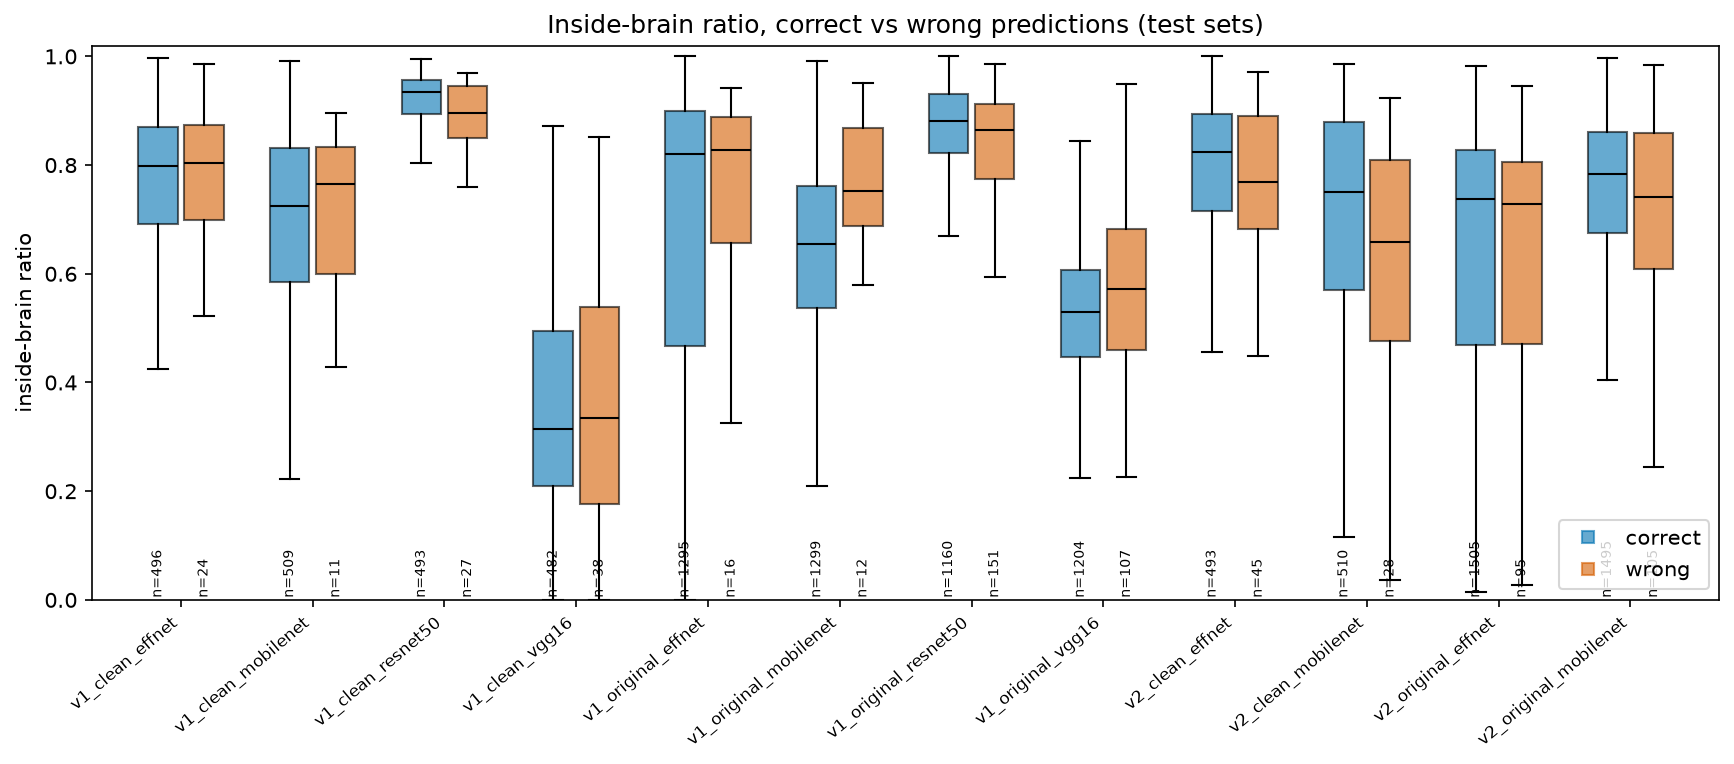

In [10]:
display(ShowImage(str(gc.plot_correct_vs_wrong(df, PLOTS))))

## 5. Galleries: 12 test images, half of them wrong predictions
Picked **at random** (seed 42), not by hand. Heat = Grad-CAM of the predicted class, cyan line = brain mask, frame colour + the word OK / WRONG = outcome.
Shown for the smallest model (MobileNetV3-S), a heavy model (ResNet-50) and VGG16, the model with the lowest ratio in the smoke test.

mobilenetv3_small_100 | wrong in gallery: 6 of 12 | wrong in the whole test set: 11


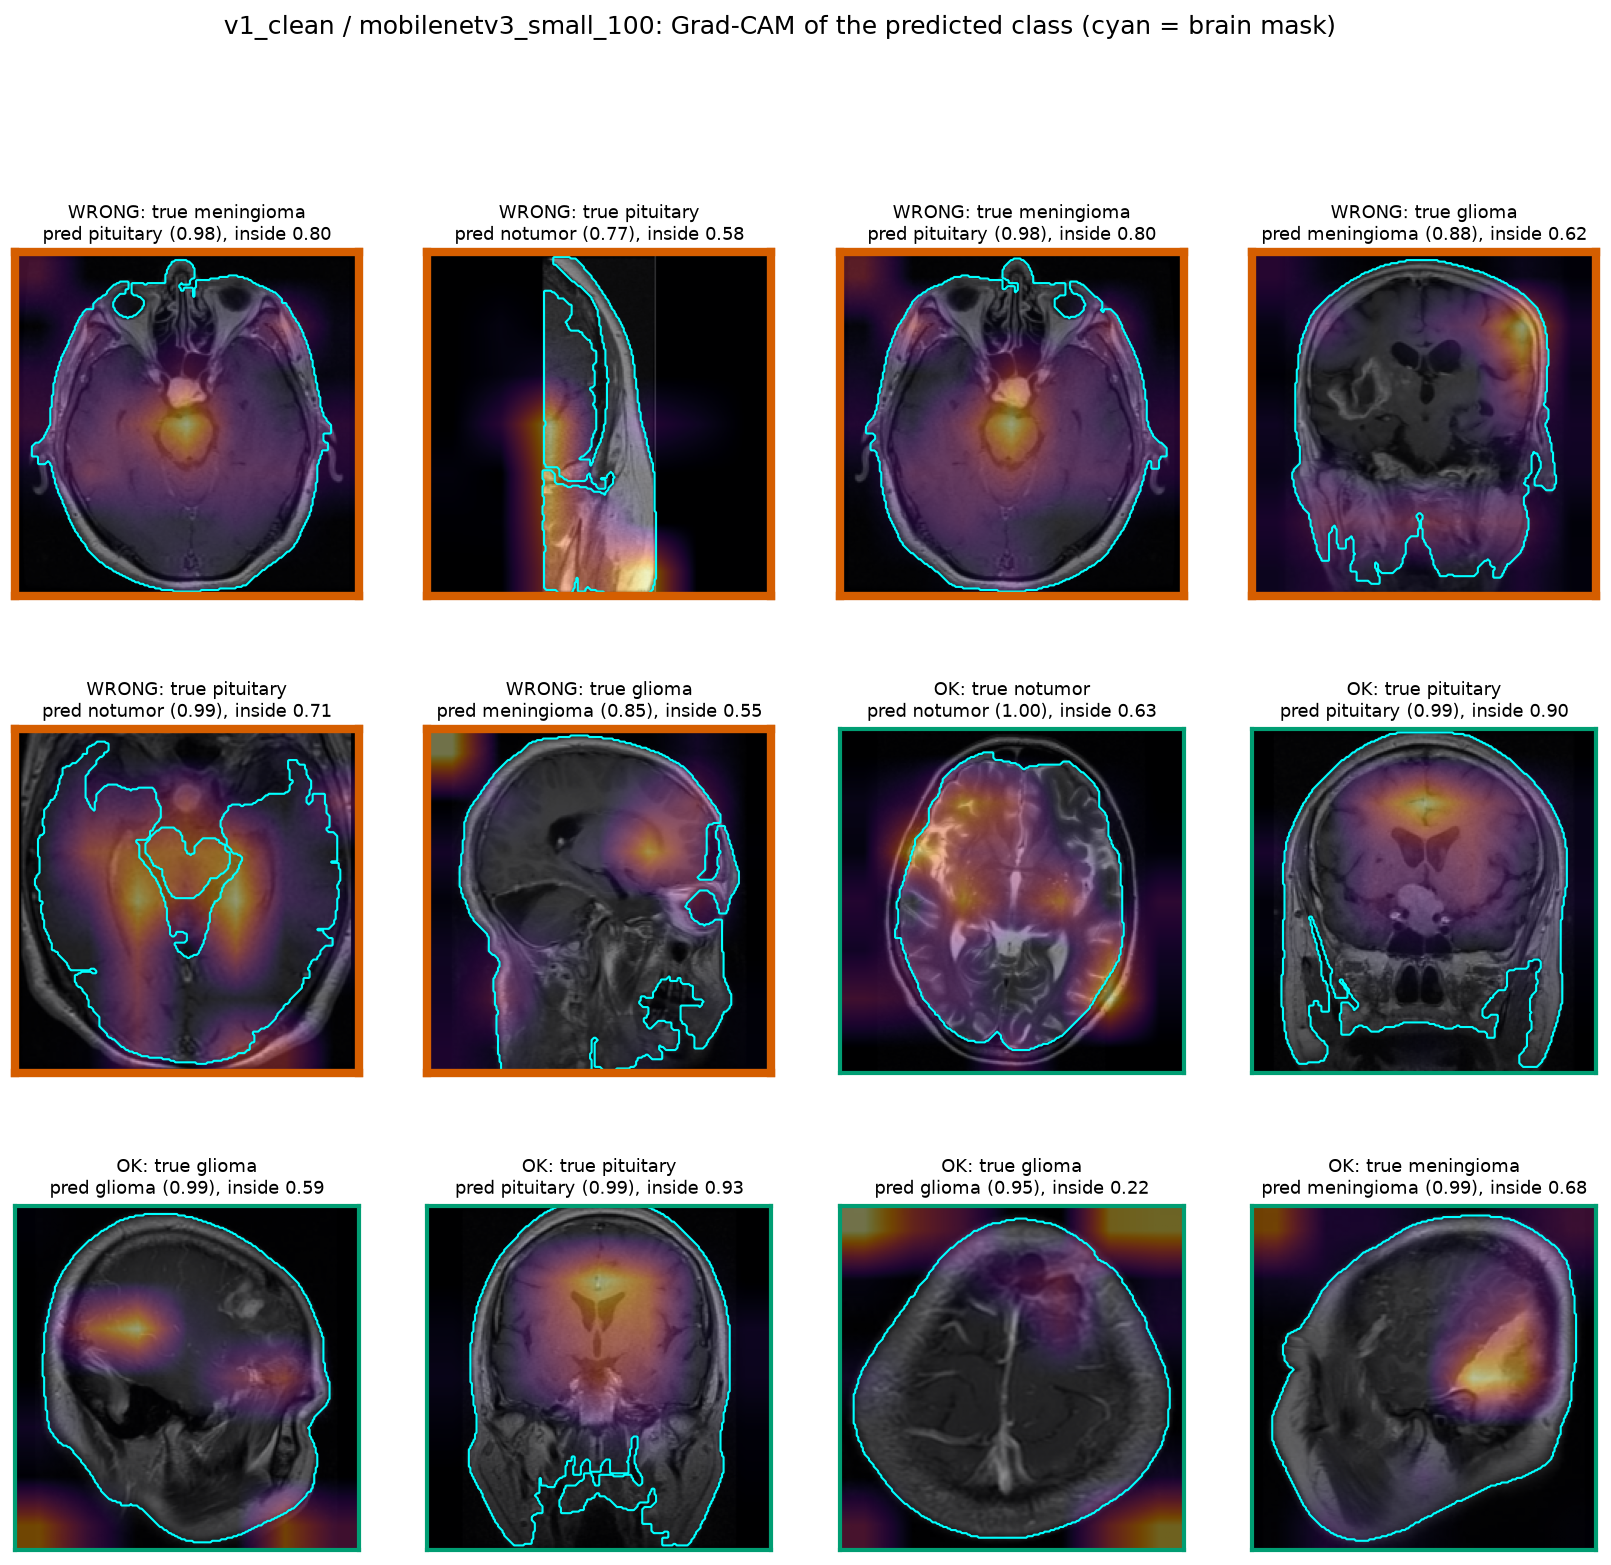

resnet50 | wrong in gallery: 6 of 12 | wrong in the whole test set: 27


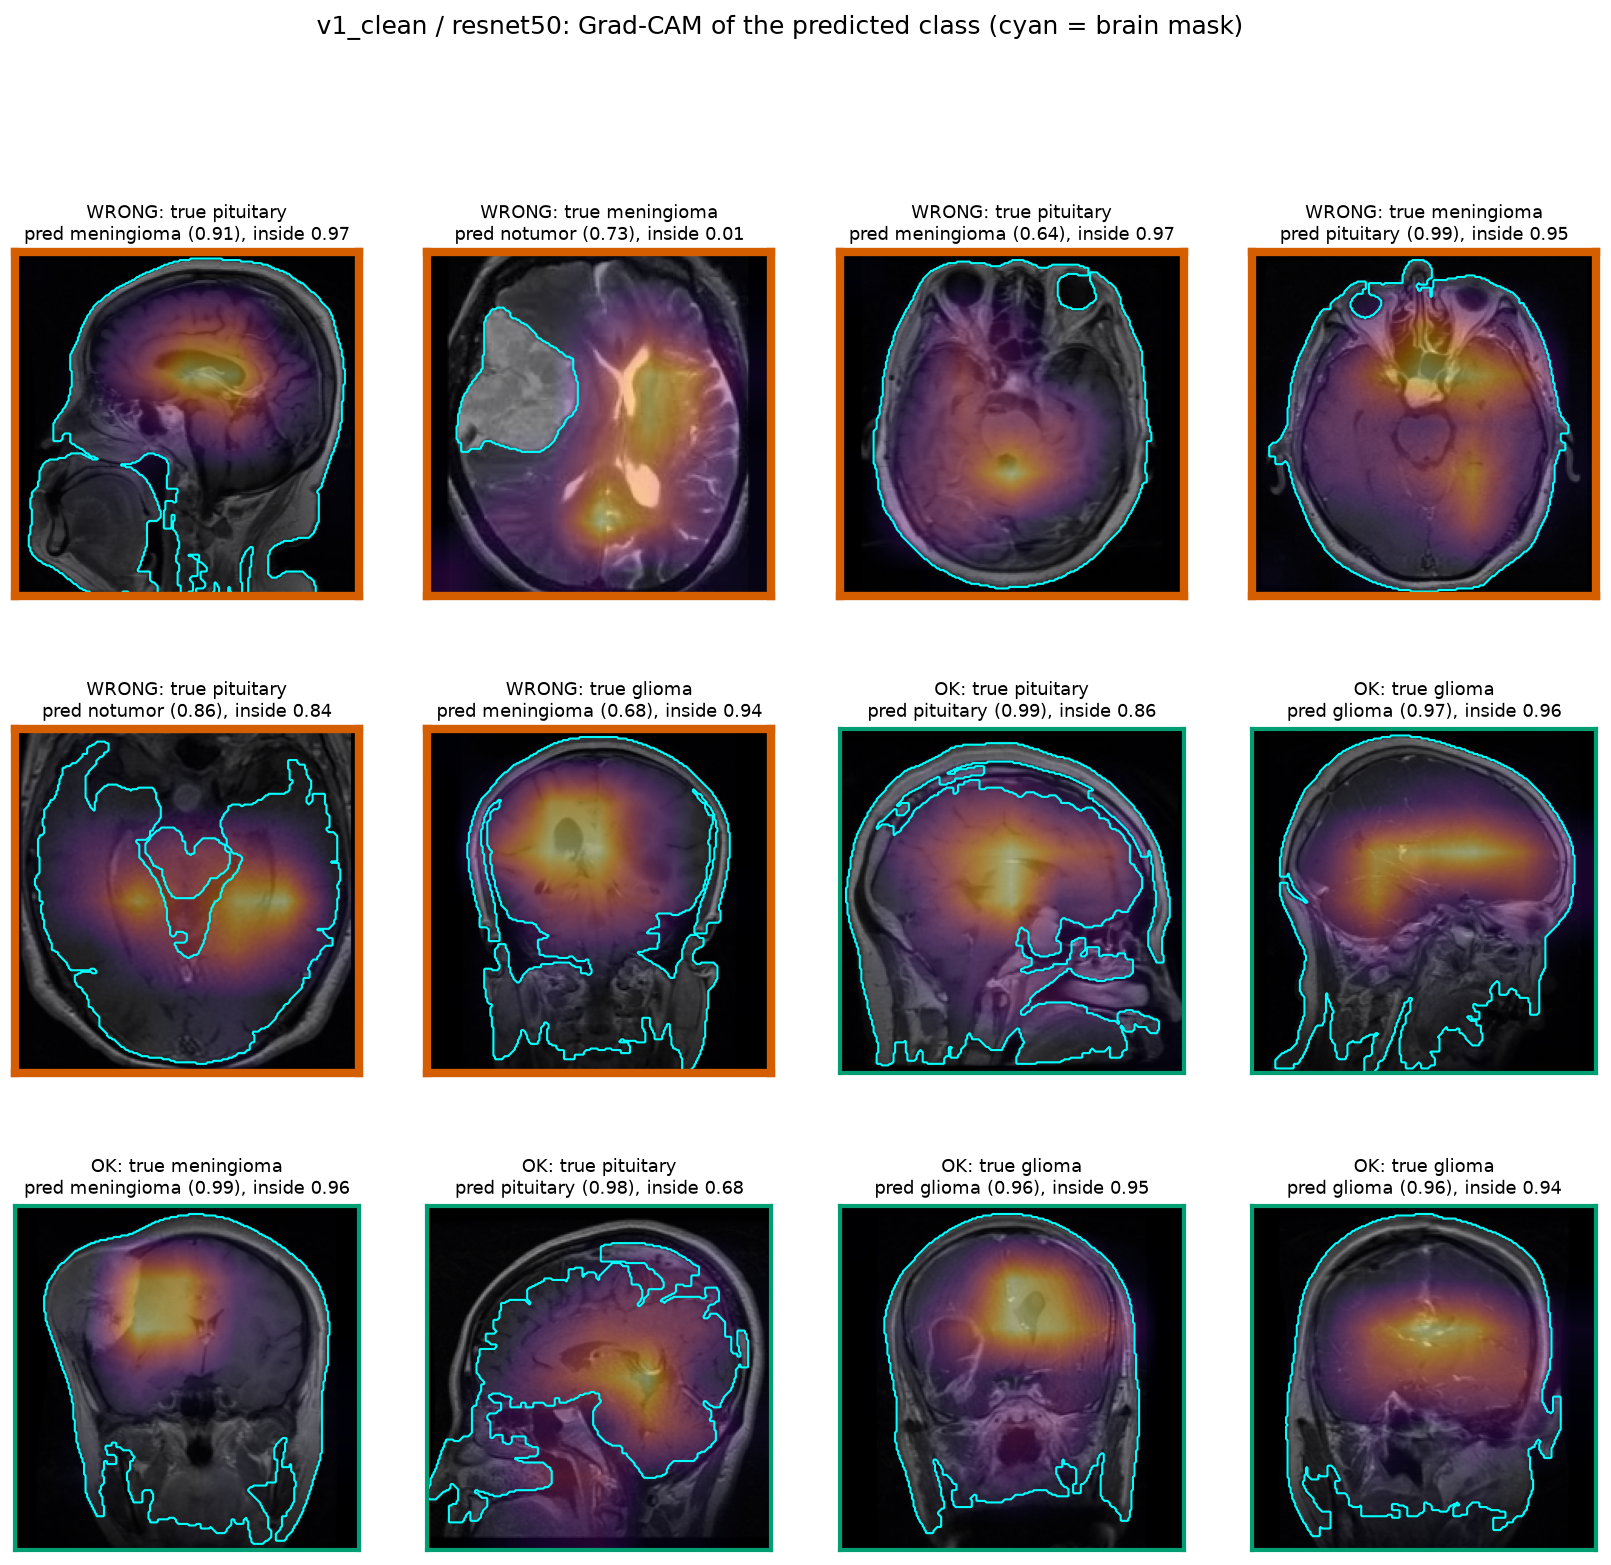

vgg16 | wrong in gallery: 6 of 12 | wrong in the whole test set: 38


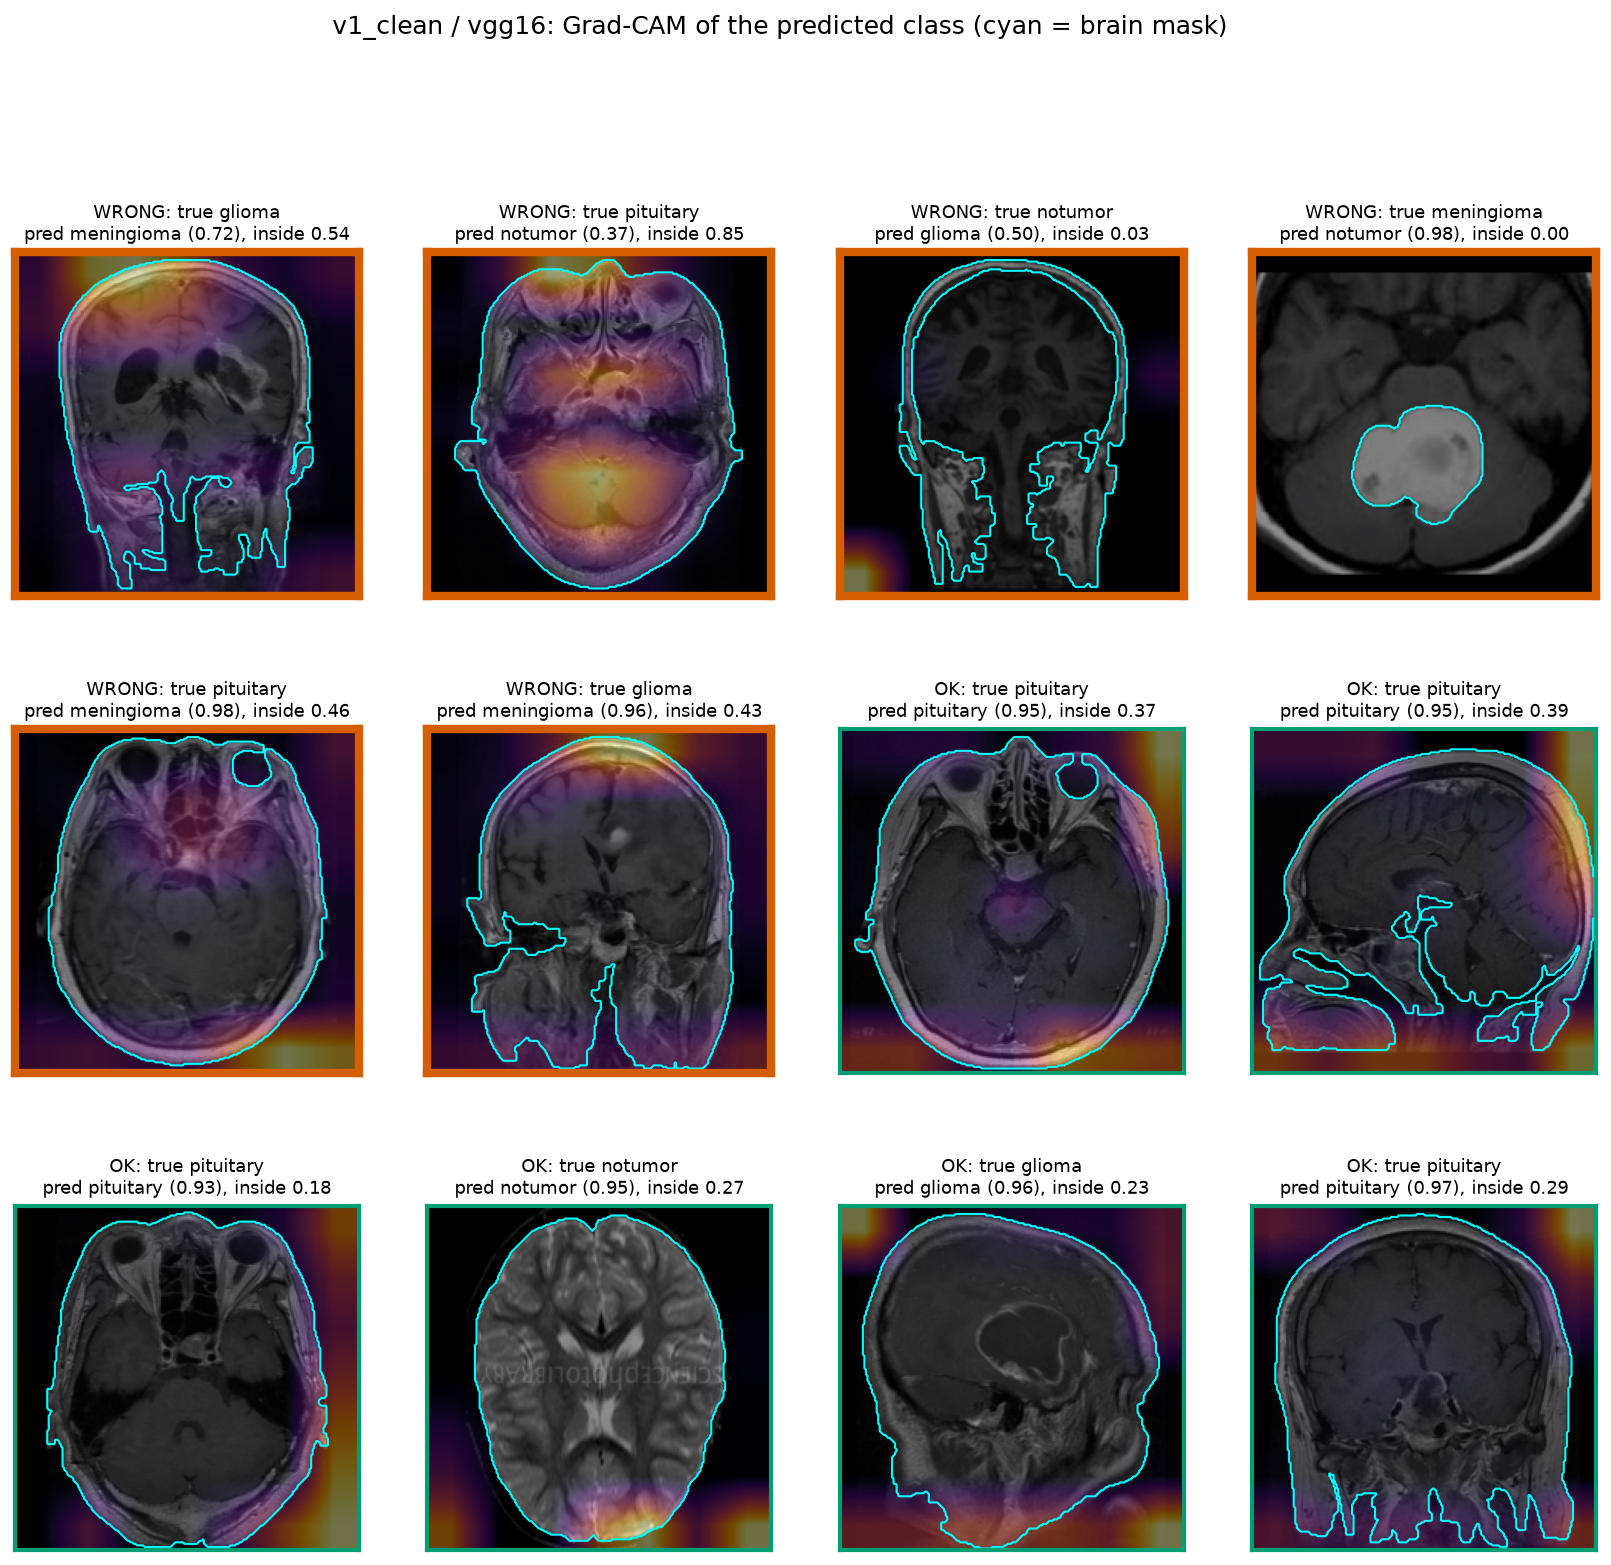

In [11]:
for model in ['mobilenetv3_small_100', 'resnet50', 'vgg16']:
    d = df[df['run'] == 'v1_clean_' + model].reset_index(drop=True)
    picks = gc.pick_gallery(d)
    print(model, '| wrong in gallery:', int((~picks['correct']).sum()), 'of', len(picks), '| wrong in the whole test set:', int((~d['correct']).sum()))
    display(ShowImage(str(gc.plot_gallery(RUNS / 'v1_clean' / model, picks, PLOTS))))

## What we found

Every number below is read from the tables above (single seed, all 11,600 test images of 12 runs; Grad-CAM class = the Week-8 prediction for every image).

**The "brain mask" is really a head-tissue mask, and it fails on some images.** Otsu + largest blob + filled holes keeps skull, scalp and neck as well as brain (see the galleries), and on images where the tumour is much brighter than the rest it keeps only the tumour (masks of 1-9% of the picture, section 1). 267 of 11,600 images (2.3%) have a mask below 25% of the picture; removing them changes the per-run mean ratio by at most 0.015, so the tables are not driven by them. A ratio of 1 means "all heat on head tissue", not "all heat on the tumour".

**Ratio per model (mean over test images; the chance level for a uniform heat map is about 0.57-0.58).**
ResNet-50 is highest: 0.899 (v1 clean), 0.849 (v1 original), with a median of 1.54 and 1.49 times chance.
EfficientNet-B0: 0.760 and 0.701 (v1), 0.783 and 0.652 (v2).
MobileNetV3-S: 0.686 and 0.638 (v1), 0.700 and 0.749 (v2).
VGG16 is the only model **below** chance: 0.353 on v1 clean (median 0.52 times chance) and 0.531 on v1 original (0.91 times chance). In the VGG16 gallery the heat sits on the skull rim, the picture borders and the bottom of the picture rather than on the brain interior. A second target layer (14 x 14) gave a similarly low mean ratio on a 16-image check (0.35, against 0.39 for the 7 x 7 layer), so it does not look like a layer-choice artefact; whether VGG16 really relies on the background was not tested causally (for example by masking it out), so this is a warning sign, not a proof.

**The ranking does not follow model size or accuracy.** By ratio: ResNet-50 > EfficientNet-B0 > MobileNetV3-S > VGG16, which is not light-versus-heavy. ResNet-50 has the highest ratio but a lower test accuracy (0.948 on v1 clean) than MobileNetV3-S (0.979, ratio 0.686). So in these runs a higher inside-brain ratio does not mean a better classifier, and our idea that lightweight models might look at the brain more than heavy ones is not supported.

**Correct vs wrong predictions: no consistent difference.** The mean ratio of wrong predictions is lower than that of correct ones in 7 of 12 runs and higher in 5 (for example v1 clean: ResNet-50 0.838 wrong vs 0.903 correct, n = 27 wrong; MobileNetV3-S 0.717 vs 0.686, n = 11; VGG16 0.355 vs 0.353, n = 38). The wrong groups are small (11 to 151 images), so we cannot claim that errors come from looking outside the brain.

**Per class.** The notumor class often has the lowest ratio, for example EfficientNet-B0 on v1 original 0.385 and on v2 original 0.337 (chance about 0.54), which is below what a uniform heat map would give; a scan without a tumour has nothing to localise, so a low value is less alarming there. ResNet-50 stays at 0.795 or above for every class.

**Original vs clean.** The ratio is higher on the clean split for EfficientNet-B0, ResNet-50 and v1 MobileNetV3-S, but lower for v2 MobileNetV3-S (0.700 vs 0.749) and for VGG16 (0.353 vs 0.531). The test sets also differ in class mix (notumor is 11% of the v1 clean test set but 31% of the v1 original one), and notumor has its own ratio behaviour, so this comparison is confounded.

**Limits.** The 7 x 7 Grad-CAM map is coarse and bleeds across the mask edge, which lowers every ratio a little. Grad-CAM is a qualitative explanation of one forward pass, not proof of what the network uses. One seed, one mask definition.